# Convergent cross mapping (CCM) entre TPM y EPM, con prueba de sustitutos

**Idea del CCM (Sugihara et al., 2012).** Si una serie $X$ influye en otra $Y$, la historia de $Y$ guarda huellas de $X$. Entonces, con la "forma" de la dinámica reconstruida a partir de $Y$ (su **variedad sombra**) se puede estimar $X$. Si esa estimación mejora al usar más datos (**convergencia**), es evidencia de acoplamiento.

**Consecuencia sobre la dirección.** Para detectar la influencia **TPM → EPM** se usa la **variedad del EPM para estimar el TPM**. La dirección del cálculo es la inversa de la dirección de influencia que se busca.

| Cálculo | Qué detecta | Papel en este cuaderno |
|---|---|---|
| Variedad EPM → estima TPM | Huella de TPM → EPM | **Dirección de interés** |
| Variedad TPM → estima EPM | Huella de EPM → TPM | Dirección de control |

**Qué NO responde:**
- No es causalidad física.
- Si las dos series las mueve un mismo factor (por ejemplo, la deformación del macizo), el CCM puede salir alto en **ambas** direcciones (Sugihara et al., 2012, discuten este caso de sincronía).
- No demuestra utilidad para imputar la brecha.

**Datos:** `Data_limpia_completa/`, tramo previo a la brecha, rejilla de 6 h. Es la misma construcción de `te gaussiana.ipynb`, en niveles y en diferencias.

## Problemas de los datos que condicionan el método (diagnosticados el 2026-10-22)

1. **Cuantización del EPM.** En 885 lecturas, cada sensor toma muy pocos valores distintos: Sensor 1, 16; Sensor 2, 42; Sensor 3, 22; Sensor 4, 10. Muchos vectores de la variedad del EPM son idénticos o equidistantes, y "los E+1 vecinos más cercanos" queda mal definido. **Esto afecta a la dirección de interés.** Solución adoptada: incluir **todos** los vecinos empatados (sección 3). Se reporta cuántos vecinos se usaron en promedio y cuántos vectores distintos tiene cada variedad.
2. **Tendencia en niveles.** Las series tardan de 30 a 177 pasos en perder su autocorrelación. Para que los "vecinos" no sean simples vecinos temporales, se excluye una ventana temporal alrededor de cada punto (ventana de Theiler), de ancho igual al tiempo de decorrelación.

## Referencias

**[verificar]** = no contrastada contra el original.
- **Sugihara, G., May, R., Ye, H., Hsieh, C., Deyle, E., Fogarty, M. y Munch, S. (2012).** Detecting causality in complex ecosystems. *Science* 338(6106), 496–500 (clave `sugihara2012`). Define el CCM.
- **Sugihara, G. y May, R. M. (1990).** Nonlinear forecasting as a way of distinguishing chaos from measurement error in time series. *Nature* 344, 734–741. **[verificar]** Proyección simplex: E+1 vecinos y pesos exponenciales.
- **Theiler, J. (1986).** Spurious dimension from correlation integrals of nearly continuous data. *Phys. Rev. A* 34, 2427–2432. **[verificar]** Exclusión de vecinos temporales.
- **Theiler, J. et al. (1992)**, *Physica D* 58, 77–94, y **Kugiumtzis, D. (2013)**, arXiv:1303.6454: sustitutos por barajado y por desplazamiento circular (ver `te gaussiana.ipynb`).
- **Venables, W. N. y Ripley, B. D.**, paquete R `class`, función `knn`, argumento `use.all`: inclusión de todos los empatados en vecinos cercanos. **[verificar]** Precedente de la regla de empates. Aplicarla al CCM es una decisión propia.

In [2]:
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ---------------- Constantes ----------------
ARCHIVO_EPM = 'Data_limpia_completa/EPM_completo.csv'
ARCHIVO_TPM = 'Data_limpia_completa/TPM_completo.csv'
BRECHA_INICIO = pd.Timestamp('2023-06-20')
PASO_H = 6

E_MAX = 10               # mayor dimension de embedding que se prueba
TOL_EMPATE = 1e-9        # tolerancia numerica para considerar dos distancias iguales
N_SUR = 199              # sustitutos por prueba -> p minimo 0.005
MIN_SHIFT = 56           # desplazamiento circular minimo, igual que en te gaussiana.ipynb
L_MIN = 50               # menor tamano de biblioteca en la curva de convergencia
N_L = 8                  # puntos de la curva rho(L)
N_MUESTRAS_L = 20        # bibliotecas aleatorias por cada L
ALFA = 0.05
SEMILLA = 2026

ARCHIVO_RESULTADOS = 'ccm_resultados.csv'
IMG_DIR = Path('img')
IMG_DIR.mkdir(exist_ok=True)

series_tpm = ['POT(1)', 'POT(2)', 'POT(3)', 'POT(4)', 'POT(5)', 'POT(6)', 'POT(7)',
              'Tilt(1)', 'Tilt(2)', 'Tilt(3)', 'Tilt(4)', 'Tilt(5)', 'Tilt(6)', 'Tilt(7)']
series_epm = ['Sensor 1 (5m)', 'Sensor 2 (10m)', 'Sensor 3 (5m)', 'Sensor 4 (10m)']

## 1. Datos

In [3]:
epm_raw = pd.read_csv(ARCHIVO_EPM, parse_dates=['date'])
tpm_raw = pd.read_csv(ARCHIVO_TPM, parse_dates=['date'])
epm_r = (epm_raw[epm_raw['date'] < BRECHA_INICIO]
         .set_index('date').sort_index().resample(f'{PASO_H}h').mean())
tpm_r = (tpm_raw[tpm_raw['date'] < BRECHA_INICIO]
         .drop(columns=['freq']).set_index('date').sort_index().resample(f'{PASO_H}h').mean())
df_niveles = epm_r.join(tpm_r, how='inner')
VERSIONES = {'niveles': df_niveles.reset_index(drop=True),
             'diferencias': df_niveles.diff().iloc[1:].reset_index(drop=True)}
print(f'Posiciones de 6 h: {len(df_niveles)}  |  filas con NaN: {df_niveles.isna().any(axis=1).sum()}')
print('Valores distintos por sensor EPM (niveles):',
      {s: df_niveles[s].nunique() for s in series_epm})

Posiciones de 6 h: 889  |  filas con NaN: 4
Valores distintos por sensor EPM (niveles): {'Sensor 1 (5m)': 16, 'Sensor 2 (10m)': 42, 'Sensor 3 (5m)': 22, 'Sensor 4 (10m)': 10}


## 2. Cómo funciona el cross-map (proyección simplex)

Para estimar la serie objetivo $x$ en el instante $t$ usando la variedad de $y$:

1. **Variedad sombra.** Cada instante se representa con el vector de las últimas $E$ lecturas de $y$: $\mathbf{y}_t=(y_t, y_{t-1},\dots,y_{t-E+1})$. Las filas con NaN se descartan.
2. **Vecinos.** Se buscan los $E+1$ vectores más cercanos a $\mathbf{y}_t$ (distancia euclidiana). $E+1$ es el mínimo número de puntos que rodea a uno en dimensión $E$ (Sugihara y May, 1990). Se excluyen los vectores con $\lvert t'-t\rvert\le r$ (ventana de Theiler), incluido el propio $t$.
3. **Regla de empates (decisión propia).** Si varios vectores están a la misma distancia que el $(E+1)$-ésimo, **se incluyen todos**. Los vectores pueden ser idénticos, pero el valor de $x$ en sus fechas no lo es; escoger solo algunos haría el resultado arbitrario.
4. **Pesos.** $w_i\propto e^{-d_i/d_1}$, con $d_1$ la menor distancia (Sugihara y May, 1990). Si $d_1=0$ (vectores idénticos al de $t$), se da peso 1 a los de distancia 0 y peso 0 al resto, y se promedian.
5. **Estimación.** $\hat x_t=\sum_i w_i\,x_{t_i}$, el promedio ponderado de $x$ en las fechas de los vecinos.
6. **Habilidad.** $\rho=\mathrm{corr}(x_t,\hat x_t)$ sobre todos los $t$.

**Convergencia.** Se repite usando bibliotecas aleatorias de tamaño $L$ (solo $L$ vectores disponibles como vecinos), para $L$ entre `L_MIN` y el total. Si $\rho(L)$ crece con $L$, la estimación mejora con más datos, como exige el criterio de Sugihara et al. (2012). Se resume con $\Delta\rho=\rho(L_{max})-\rho(L_{min})$.

Con la biblioteca completa, los vecinos y pesos dependen **solo de la variedad**, no del objetivo. Por eso cada sustituto del objetivo se evalúa casi sin costo: la matriz de pesos se calcula una vez.

In [4]:
def embeber(v, E):
    n = len(v)
    M = np.full((n, E), np.nan)
    for j in range(E):
        M[j:, j] = v[:n - j]
    return M, ~np.isnan(M).any(axis=1)


def distancias(M, valido, r):
    """Distancias entre vectores validos; |t - t'| <= r -> infinito (ventana de Theiler)."""
    idx = np.where(valido)[0]
    V = M[idx]
    D = np.sqrt(np.maximum(((V[:, None, :] - V[None, :, :]) ** 2).sum(-1), 0))
    D[np.abs(idx[:, None] - idx[None, :]) <= r] = np.inf
    return idx, D


def pesos_simplex(D, k):
    """Pesos de los k vecinos mas cercanos MAS todos los empatados con el k-esimo."""
    ok = np.isfinite(D).sum(axis=1) >= k
    dk = np.full(D.shape[0], np.nan)
    dk[ok] = np.partition(D[ok], k - 1, axis=1)[:, k - 1]
    sel = D <= (dk[:, None] * (1 + TOL_EMPATE) + TOL_EMPATE)
    sel[~ok] = False
    d1 = np.where(sel, D, np.inf).min(axis=1)
    cero = ok & (d1 <= TOL_EMPATE)
    with np.errstate(divide='ignore', invalid='ignore'):
        W = np.where(sel, np.exp(-D / np.where(d1 > 0, d1, 1)[:, None]), 0.0)
    W[cero] = np.where(sel[cero] & (D[cero] <= TOL_EMPATE), 1.0, 0.0)
    s = W.sum(axis=1, keepdims=True)
    W = np.divide(W, s, out=np.zeros_like(W), where=s > 0)
    return W, ok, sel.sum(axis=1)


def estimar(W, filas_ok, objetivo_lib):
    """Promedio ponderado del objetivo en los vecinos (ignora NaN del objetivo)."""
    m = ~np.isnan(objetivo_lib)
    num = W @ np.where(m, objetivo_lib, 0.0)
    den = W @ m.astype(float)
    est = np.full(W.shape[0], np.nan)
    good = filas_ok & (den > 0)
    est[good] = num[good] / den[good]
    return est


def rho(obs, est):
    ok = ~np.isnan(obs) & ~np.isnan(est)
    return float(np.corrcoef(obs[ok], est[ok])[0, 1]) if ok.sum() >= 3 else np.nan


def tiempo_decorrelacion(v):
    """Primer rezago en que la autocorrelacion cae por debajo de 1/e (ancho de la ventana de Theiler)."""
    v = v[~np.isnan(v)] - np.nanmean(v)
    d = np.dot(v, v)
    for l in range(1, len(v) // 2):
        if np.dot(v[:-l], v[l:]) / d < 1 / np.e:
            return l
    return len(v) // 4


def elegir_E(v, r, e_max=E_MAX):
    """Proyeccion simplex univariada a un paso: E que maximiza rho(v_{t+1}, estimacion)."""
    rhos = []
    for E in range(1, e_max + 1):
        M, valido = embeber(v, E)
        valido = valido.copy()
        valido[-1] = False                     # la ultima fila no tiene futuro
        idx, D = distancias(M, valido, r)
        W, ok, _ = pesos_simplex(D, E + 1)
        futuro = v[idx + 1]
        rhos.append(rho(futuro, estimar(W, ok, futuro)))
    return int(np.nanargmax(rhos)) + 1, np.array(rhos)


class Variedad:
    """Variedad sombra de una serie, lista para hacer cross-map hacia cualquier objetivo."""

    def __init__(self, v, E, r):
        self.E, self.r = E, r
        M, valido = embeber(v, E)
        self.idx, self.D = distancias(M, valido, r)
        self.n_vectores = len(self.idx)
        self.n_distintos = len(np.unique(M[valido], axis=0))
        self.W, self.ok, nv = pesos_simplex(self.D, E + 1)
        self.vecinos_prom = float(nv[self.ok].mean())

    def skill(self, objetivo):
        o = objetivo[self.idx]
        return rho(o, estimar(self.W, self.ok, o))

    def curva(self, objetivo, L_grid, n_muestras, rng):
        o = objetivo[self.idx]
        n = len(self.idx)
        medias = []
        for L in L_grid:
            vals = []
            for _ in range(n_muestras):
                lib = rng.choice(n, size=int(L), replace=False)
                W, ok, _ = pesos_simplex(self.D[:, lib], self.E + 1)
                vals.append(rho(o, estimar(W, ok, o[lib])))
            medias.append(np.nanmean(vals))
        return np.array(medias)

## 3. Validación contra pyEDM

Se compara la habilidad del cross-map con `pyEDM.Simplex` (Tp = 0, biblioteca = predicción, misma ventana de exclusión) en un tramo sin NaN, usando como variedad una serie TPM. El TPM casi no tiene empates, así que los dos cálculos deben coincidir. Una diferencia pequeña solo puede venir de los pocos empates que esta implementación incluye y pyEDM no.

In [5]:
import pyEDM

tramo = VERSIONES['niveles'].iloc[260:630].reset_index(drop=True)
x_val, y_val = tramo['Tilt(4)'].values, tramo['Sensor 1 (5m)'].values
n_val = len(tramo)
d_val = pd.DataFrame({'Time': np.arange(1, n_val + 1), 'X': x_val, 'Y': y_val})
for E, r in [(3, 0), (5, 10)]:
    propio = Variedad(x_val, E, r).skill(y_val)
    s = pyEDM.Simplex(dataFrame=d_val, columns='X', target='Y', lib=f'1 {n_val}', pred=f'1 {n_val}',
                      E=E, Tp=0, exclusionRadius=r)
    s = s[['Observations', 'Predictions']].dropna()
    print(f'E={E}, r={r}:  propio rho = {propio:.6f}  |  pyEDM rho = {np.corrcoef(s.Observations, s.Predictions)[0, 1]:.6f}')

E=3, r=0:  propio rho = 0.540323  |  pyEDM rho = 0.539714
E=5, r=10:  propio rho = 0.542949  |  pyEDM rho = 0.542949


## 4. Parámetros de cada variedad: ventana de Theiler $r$ y dimensión $E$

Para cada una de las 18 series y cada versión:
- $r$ = tiempo de decorrelación (primer rezago con autocorrelación < $1/e$).
- $E$ = el que maximiza la predicción simplex a un paso (Sugihara y May, 1990).
- Diagnóstico de cuantización: cuántos vectores distintos tiene la variedad y cuántos vecinos se usan en promedio. Si fueran exactamente $E+1$, no habría empates.

In [6]:
VARIEDADES = {}
filas = []
for version, d in VERSIONES.items():
    for serie in series_epm + series_tpm:
        v = d[serie].values
        r = tiempo_decorrelacion(v)
        E, _ = elegir_E(v, r)
        var = Variedad(v, E, r)
        VARIEDADES[(version, serie)] = var
        filas.append({'version': version, 'serie': serie, 'r_pasos': r, 'r_horas': r * PASO_H, 'E': E,
                      'vectores': var.n_vectores, 'vectores_distintos': var.n_distintos,
                      'vecinos_prom': round(var.vecinos_prom, 1), 'E+1': E + 1})
tabla_variedades = pd.DataFrame(filas)
tabla_variedades

,version,serie,r_pasos,r_horas,E,vectores,vectores_distintos,vecinos_prom,E+1
0,niveles,Sensor 1 (5m),177,1062,5,865,502,7.3,6
1,niveles,Sensor 2 (10m),11,66,10,840,840,11.0,11
2,niveles,Sensor 3 (5m),61,366,9,845,845,10.1,10
3,niveles,Sensor 4 (10m),62,372,4,870,99,72.7,5
4,niveles,POT(1),173,1038,1,889,730,2.1,2
5,niveles,POT(2),117,702,2,888,888,3.0,3
6,niveles,POT(3),190,1140,1,889,889,2.0,2
7,niveles,POT(4),62,372,5,885,885,6.0,6
8,niveles,POT(5),119,714,4,886,886,5.0,5
9,niveles,POT(6),22,132,5,885,885,6.0,6


## 5. Prueba de sustitutos y batería

**Estadístico:** $\rho$ con la biblioteca completa.

**Sustitutos:** se alteran solo los de la **serie que se estima** (el objetivo). La variedad queda intacta. Son los mismos dos tipos y parámetros que en `te gaussiana.ipynb`:
- **Barajado:** destruye toda la estructura temporal del objetivo.
- **Desplazamiento circular:** conserva la autocorrelación del objetivo y solo rompe su alineación con la variedad. Desplazamiento mínimo de 56 pasos.

$p=(1+b)/(M+1)$, donde $b$ es el número de sustitutos con $\rho\ge$ al observado.

**Criterio de "pasa el CCM":** $p_{desplazamiento}<0.05$ **y** $\Delta\rho>0$ (convergencia). La convergencia se usa como requisito descriptivo, sin prueba formal propia.

Se calculan las dos direcciones para los 56 pares y las dos versiones. Tarda unos 8 minutos. Los resultados se guardan en `ccm_resultados.csv`; si el archivo existe, se carga.

In [8]:
def nulas(var, objetivo, rng, n_sur=N_SUR, min_shift=MIN_SHIFT):
    n = len(objetivo)
    nb = np.array([var.skill(rng.permutation(objetivo)) for _ in range(n_sur)])
    nd = np.array([var.skill(np.roll(objetivo, rng.integers(min_shift, n - min_shift + 1))) for _ in range(n_sur)])
    return nb, nd


def p_valor(nula, obs):
    return (1 + int(np.sum(nula >= obs))) / (len(nula) + 1)


if Path(ARCHIVO_RESULTADOS).exists():
    resultados = pd.read_csv(ARCHIVO_RESULTADOS)
    print(f'Cargado desde cache: {ARCHIVO_RESULTADOS}')
else:
    rng = np.random.default_rng(SEMILLA)
    filas = []
    t0 = time.time()
    for version, d in VERSIONES.items():
        for epm_col in series_epm:
            for tpm_col in series_tpm:
                for direccion, var_serie, obj_serie in [('interes: EPM estima TPM', epm_col, tpm_col),
                                                        ('control: TPM estima EPM', tpm_col, epm_col)]:
                    var = VARIEDADES[(version, var_serie)]
                    objetivo = d[obj_serie].values
                    obs = var.skill(objetivo)
                    L_grid = np.linspace(L_MIN, var.n_vectores, N_L).astype(int)
                    curva = var.curva(objetivo, L_grid, N_MUESTRAS_L, rng)
                    nb, nd = nulas(var, objetivo, rng)
                    filas.append({'version': version, 'TPM': tpm_col, 'EPM': epm_col, 'direccion': direccion,
                                  'E': var.E, 'r_pasos': var.r, 'rho': obs,
                                  'rho_Lmin': curva[0], 'delta_rho': curva[-1] - curva[0],
                                  'p_barajado': p_valor(nb, obs), 'p_desplazamiento': p_valor(nd, obs)})
        print(f'{version}: listo ({(time.time() - t0) / 60:.1f} min)')
    resultados = pd.DataFrame(filas)
    resultados['converge'] = resultados['delta_rho'] > 0
    resultados['pasa_ccm'] = (resultados['p_desplazamiento'] < ALFA) & resultados['converge']
    resultados.to_csv(ARCHIVO_RESULTADOS, index=False)

resultados.head()

Cargado desde cache: ccm_resultados.csv


,version,TPM,EPM,direccion,E,r_pasos,rho,rho_Lmin,delta_rho,p_barajado,p_desplazamiento,converge,pasa_ccm
0,niveles,POT(1),Sensor 1 (5m),interes: EPM estima TPM,5,177,0.528537,0.490803,0.037734,0.005,0.050,True,False
1,niveles,POT(1),Sensor 1 (5m),control: TPM estima EPM,1,173,0.587099,0.561483,0.025617,0.005,0.005,True,True
2,niveles,POT(2),Sensor 1 (5m),interes: EPM estima TPM,5,177,-0.328698,-0.607453,0.278755,1.000,1.000,True,False
3,niveles,POT(2),Sensor 1 (5m),control: TPM estima EPM,2,117,-0.671216,-0.674806,0.003590,1.000,1.000,True,False
4,niveles,POT(3),Sensor 1 (5m),interes: EPM estima TPM,5,177,0.599409,0.541452,0.057957,0.005,0.005,True,True


In [9]:
resultados

,version,TPM,EPM,direccion,E,r_pasos,rho,rho_Lmin,delta_rho,p_barajado,p_desplazamiento,converge,pasa_ccm
0,niveles,POT(1),Sensor 1 (5m),interes: EPM estima TPM,5,177,0.528537,0.490803,0.037734,0.005,0.050,True,False
1,niveles,POT(1),Sensor 1 (5m),control: TPM estima EPM,1,173,0.587099,0.561483,0.025617,0.005,0.005,True,True
2,niveles,POT(2),Sensor 1 (5m),interes: EPM estima TPM,5,177,-0.328698,-0.607453,0.278755,1.000,1.000,True,False
3,niveles,POT(2),Sensor 1 (5m),control: TPM estima EPM,2,117,-0.671216,-0.674806,0.003590,1.000,1.000,True,False
4,niveles,POT(3),Sensor 1 (5m),interes: EPM estima TPM,5,177,0.599409,0.541452,0.057957,0.005,0.005,True,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...
219,diferencias,Tilt(5),Sensor 4 (10m),control: TPM estima EPM,9,1,0.104454,0.109269,-0.004815,0.005,0.310,False,False
220,diferencias,Tilt(6),Sensor 4 (10m),interes: EPM estima TPM,2,1,0.304128,0.200534,0.103594,0.005,0.005,True,True
221,diferencias,Tilt(6),Sensor 4 (10m),control: TPM estima EPM,8,1,0.151594,0.070189,0.081406,0.005,0.010,True,True
222,diferencias,Tilt(7),Sensor 4 (10m),interes: EPM estima TPM,2,1,-0.028041,-0.002567,-0.025475,0.650,0.805,False,False


## 6. Resumen

In [10]:
resumen = (resultados.groupby(['version', 'direccion'])
           .agg(p_barajado_menor_005=('p_barajado', lambda s: int((s < ALFA).sum())),
                p_desplazamiento_menor_005=('p_desplazamiento', lambda s: int((s < ALFA).sum())),
                convergen=('converge', 'sum'),
                pasa_ccm=('pasa_ccm', 'sum'),
                rho_mediana=('rho', 'median'),
                rho_max=('rho', 'max'))
           .round(3))
resumen['esperado por azar'] = round(56 * ALFA, 1)
resumen

p_barajado_menor_005  \
version     direccion                                       
diferencias control: TPM estima EPM                    40   
            interes: EPM estima TPM                    30   
niveles     control: TPM estima EPM                    38   
            interes: EPM estima TPM                    42   

                                     p_desplazamiento_menor_005  convergen  \
version     direccion                                                        
diferencias control: TPM estima EPM                          27         44   
            interes: EPM estima TPM                          27         46   
niveles     control: TPM estima EPM                          20         45   
            interes: EPM estima TPM                          15         49   

                                     pasa_ccm  rho_mediana  rho_max  \
version     direccion                                                 
diferencias control: TPM estima EPM        26        0.123    0.635   
            interes: EPM estima TPM        27        0.098    0.641   
niveles     control: TPM estima EPM        19        0.248    0.837   
            interes: EPM estima TPM        14        0.218    0.649   

                                     esperado por azar  
version     direccion                                   
diferencias control: TPM estima EPM                2.8  
            interes: EPM estima TPM                2.8  
niveles     control: TPM estima EPM                2.8  
            interes: EPM estima TPM                2.8

In [11]:
# Pares que pasan el CCM en la direccion de interes, con el resultado de la direccion de control al lado
interes = resultados[resultados['direccion'].str.startswith('interes')].set_index(['version', 'TPM', 'EPM'])
control = resultados[resultados['direccion'].str.startswith('control')].set_index(['version', 'TPM', 'EPM'])
comparado = interes[['E', 'r_pasos', 'rho', 'delta_rho', 'p_desplazamiento', 'pasa_ccm']].join(
    control[['rho', 'delta_rho', 'p_desplazamiento', 'pasa_ccm']], rsuffix='_control')
comparado[comparado['pasa_ccm']].sort_values('rho', ascending=False).round(3)

E  r_pasos    rho  delta_rho  \
version     TPM     EPM                                             
niveles     POT(3)  Sensor 3 (5m)    9       61  0.649      0.035   
diferencias Tilt(4) Sensor 1 (5m)    9        1  0.641      0.039   
            Tilt(5) Sensor 1 (5m)    9        1  0.604      0.050   
            POT(6)  Sensor 1 (5m)    9        1  0.602      0.037   
niveles     POT(3)  Sensor 1 (5m)    5      177  0.599      0.058   
            POT(1)  Sensor 3 (5m)    9       61  0.560      0.028   
            Tilt(1) Sensor 3 (5m)    9       61  0.536      0.025   
            POT(4)  Sensor 4 (10m)   4       62  0.534      0.060   
            Tilt(4) Sensor 4 (10m)   4       62  0.525      0.151   
            POT(7)  Sensor 2 (10m)  10       11  0.524      0.002   
            Tilt(2) Sensor 1 (5m)    5      177  0.482      0.083   
diferencias Tilt(3) Sensor 1 (5m)    9        1  0.462      0.099   
niveles     Tilt(3) Sensor 4 (10m)   4       62  0.445      0.137   
            POT(6)  Sensor 4 (10m)   4       62  0.438      0.121   
diferencias POT(3)  Sensor 1 (5m)    9        1  0.422      0.034   
            POT(4)  Sensor 4 (10m)   2        1  0.419      0.112   
            POT(7)  Sensor 1 (5m)    9        1  0.416      0.073   
            Tilt(6) Sensor 1 (5m)    9        1  0.415      0.130   
            POT(6)  Sensor 4 (10m)   2        1  0.392      0.092   
            Tilt(2) Sensor 1 (5m)    9        1  0.370      0.013   
            Tilt(4) Sensor 4 (10m)   2        1  0.354      0.087   
niveles     Tilt(4) Sensor 3 (5m)    9       61  0.342      0.044   
diferencias POT(3)  Sensor 4 (10m)   2        1  0.340      0.102   
            Tilt(5) Sensor 4 (10m)   2        1  0.336      0.100   
niveles     POT(7)  Sensor 1 (5m)    5      177  0.336      0.227   
diferencias POT(4)  Sensor 1 (5m)    9        1  0.332      0.066   
niveles     Tilt(4) Sensor 1 (5m)    5      177  0.315      0.030   
diferencias Tilt(6) Sensor 4 (10m)   2        1  0.304      0.104   
            POT(6)  Sensor 3 (5m)    3        1  0.293      0.020   
            Tilt(1) Sensor 1 (5m)    9        1  0.282      0.089   
            Tilt(4) Sensor 3 (5m)    3        1  0.282      0.001   
            Tilt(3) Sensor 4 (10m)   2        1  0.281      0.115   
            POT(7)  Sensor 4 (10m)   2        1  0.280      0.067   
                    Sensor 3 (5m)    3        1  0.274      0.047   
            POT(3)  Sensor 3 (5m)    3        1  0.242      0.001   
            Tilt(5) Sensor 3 (5m)    3        1  0.242      0.058   
            Tilt(2) Sensor 4 (10m)   2        1  0.225      0.122   
            Tilt(1) Sensor 4 (10m)   2        1  0.192      0.098   
            POT(4)  Sensor 3 (5m)    3        1  0.180      0.021   
niveles     Tilt(5) Sensor 4 (10m)   4       62  0.180      0.155   
diferencias Tilt(6) Sensor 3 (5m)    3        1  0.122      0.032   

                                    p_desplazamiento  pasa_ccm  rho_control  \
version     TPM     EPM                                                       
niveles     POT(3)  Sensor 3 (5m)              0.005      True        0.443   
diferencias Tilt(4) Sensor 1 (5m)              0.005      True        0.635   
            Tilt(5) Sensor 1 (5m)              0.005      True        0.577   
            POT(6)  Sensor 1 (5m)              0.005      True        0.634   
niveles     POT(3)  Sensor 1 (5m)              0.005      True        0.478   
            POT(1)  Sensor 3 (5m)              0.030      True        0.246   
            Tilt(1) Sensor 3 (5m)              0.045      True        0.304   
            POT(4)  Sensor 4 (10m)             0.005      True        0.512   
            Tilt(4) Sensor 4 (10m)             0.005      True        0.704   
            POT(7)  Sensor 2 (10m)             0.030      True        0.305   
            Tilt(2) Sensor 1 (5m)              0.005      True        0.128   
diferencias Tilt(3) Sensor 1 (5m)         

## 7. Gráfica por par: convergencia y prueba de sustitutos

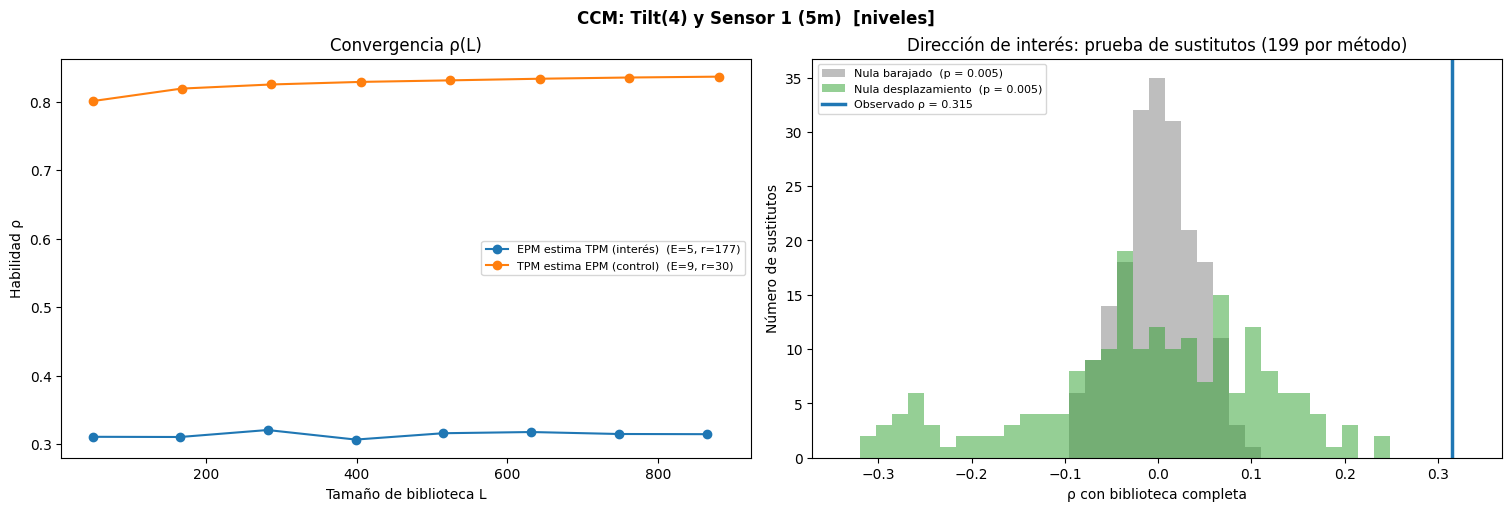

In [12]:
def graficar_par(tpm_col, epm_col, version='niveles', guardar=True):
    d = VERSIONES[version]
    rng = np.random.default_rng(SEMILLA)
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5), constrained_layout=True)
    for etiqueta, var_serie, obj_serie, color in [('EPM estima TPM (interés)', epm_col, tpm_col, 'tab:blue'),
                                                   ('TPM estima EPM (control)', tpm_col, epm_col, 'tab:orange')]:
        var = VARIEDADES[(version, var_serie)]
        objetivo = d[obj_serie].values
        L_grid = np.linspace(L_MIN, var.n_vectores, N_L).astype(int)
        ax1.plot(L_grid, var.curva(objetivo, L_grid, N_MUESTRAS_L, rng), 'o-', color=color,
                 label=f'{etiqueta}  (E={var.E}, r={var.r})')
        if etiqueta.endswith('(interés)'):
            obs = var.skill(objetivo)
            nb, nd = nulas(var, objetivo, rng)
            bins = np.linspace(min(nb.min(), nd.min(), obs) - 0.02, max(nb.max(), nd.max(), obs) + 0.02, 40)
            ax2.hist(nb, bins=bins, alpha=0.5, color='tab:gray', label=f'Nula barajado  (p = {p_valor(nb, obs):.3f})')
            ax2.hist(nd, bins=bins, alpha=0.5, color='tab:green', label=f'Nula desplazamiento  (p = {p_valor(nd, obs):.3f})')
            ax2.axvline(obs, color='tab:blue', lw=2.5, label=f'Observado ρ = {obs:.3f}')
    ax1.set_xlabel('Tamaño de biblioteca L')
    ax1.set_ylabel('Habilidad ρ')
    ax1.set_title('Convergencia ρ(L)')
    ax1.legend(fontsize=8)
    ax2.set_xlabel('ρ con biblioteca completa')
    ax2.set_ylabel('Número de sustitutos')
    ax2.set_title(f'Dirección de interés: prueba de sustitutos ({N_SUR} por método)')
    ax2.legend(fontsize=8)
    fig.suptitle(f'CCM: {tpm_col} y {epm_col}  [{version}]', fontweight='bold')
    if guardar:
        nombre = f'ccm_{version}_{tpm_col}_{epm_col}'.replace(' ', '_').replace('(', '').replace(')', '')
        fig.savefig(IMG_DIR / f'{nombre}.png', dpi=150)
    plt.show()


graficar_par('Tilt(4)', 'Sensor 1 (5m)', 'niveles')

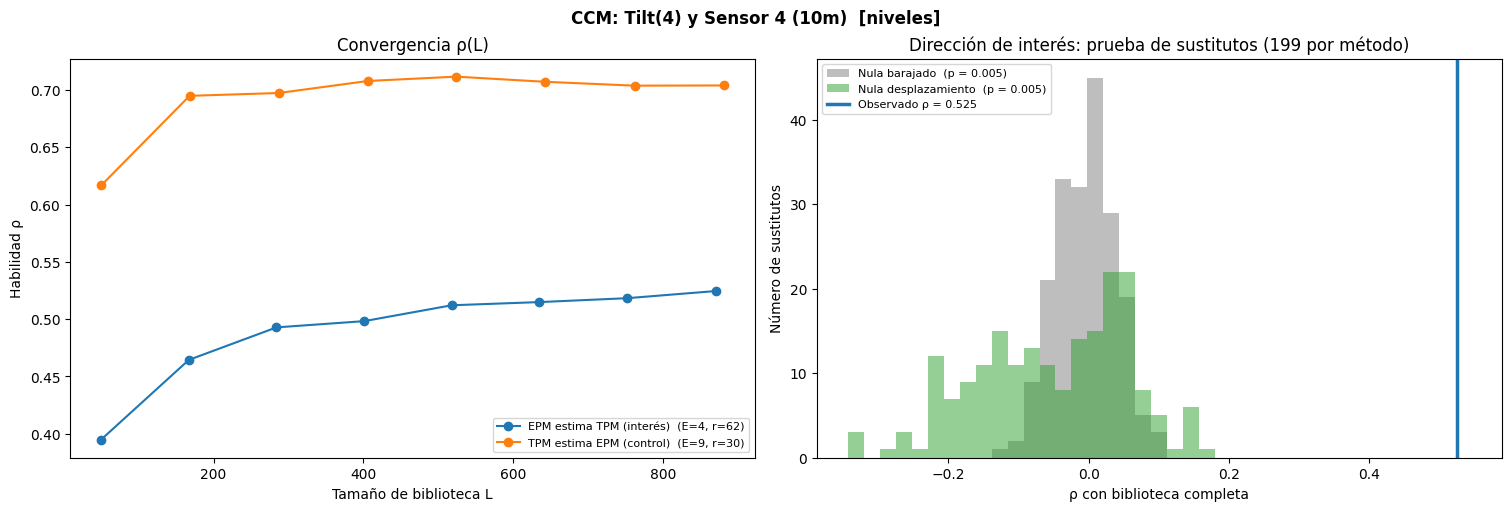

In [10]:
graficar_par('Tilt(4)', 'Sensor 4 (10m)', 'niveles')

## 8. Lectura y limitaciones

- **"Pasa el CCM" en la dirección de interés** significa que la variedad del EPM estima al TPM mejor que lo esperable sin alineación temporal, y que esa estimación mejora con más datos. En la lógica de Sugihara et al. (2012), es una huella de influencia TPM → EPM.
- **Si pasan las dos direcciones**, la lectura más prudente es **dinámica compartida**, por ejemplo un forzante común. No es influencia en un solo sentido.
- **Cuantización:** la columna `vecinos_prom` de la sección 4 muestra cuánto se aparta cada variedad de los $E+1$ vecinos teóricos. Cuanto mayor la diferencia, más suave y menos local es la estimación, y menos confiable la dirección de interés para ese sensor.
- **Ventana de Theiler en niveles:** con $r$ de hasta 177 pasos se excluye gran parte de la biblioteca para cada punto. Es el costo de no confundir tendencia con dinámica.
- **Convergencia** usada como criterio descriptivo ($\Delta\rho>0$), sin prueba formal.
- **Sin corrección por comparaciones múltiples.** Referencia: unos 2.8 pares por azar.
- **Decisiones propias:** regla de empates, $r$ por el criterio $1/e$, `E_MAX` = 10, `L_MIN` = 50, `MIN_SHIFT` = 56.